# Прогноз схвалення займу (Loan Approval Prediction)

**Final Project**

**Завдання:** за даними про клієнта (дохід, кредитна історія, сума займу тощо) передбачити, чи буде йому схвалено займ (`Loan_Status`: Y — так, N — ні).

**Структура ноутбука:**
- **Частина 1. EDA** (Exploratory Data Analysis — розвідувальний аналіз даних): знайомимось з даними, шукаємо пропуски, дивимось графіки та кореляції.
- **Частина 2. Моделювання:** готуємо дані, ділимо 80/20, навчаємо моделі (KNN, Decision Tree, Random Forest), підбираємо параметри, порівнюємо результати.

**Технології, які використано:**

| Технологія | Для чого |
|---|---|
| `pandas` | завантаження та обробка таблиці |
| `matplotlib`, `seaborn` | графіки |
| `scikit-learn` | розділення даних, Pipeline, моделі, GridSearchCV, метрики |
| `joblib` | збереження навченої моделі у файл |

## 0. Підготовка: імпорт бібліотек і завантаження файлу

**Що робимо:** підключаємо бібліотеки та завантажуємо `loan_data.csv` у Google Colab.

**Навіщо:** без бібліотек Python не вміє працювати з таблицями та моделями; без файлу немає даних.

In [105]:
# Бібліотеки для роботи з даними
import pandas as pd
import numpy as np

# Бібліотеки для графіків
import matplotlib.pyplot as plt
import seaborn as sns

# Бібліотеки для машинного навчання (scikit-learn)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import joblib

sns.set_theme(style="whitegrid")   # гарний стиль для всіх графіків

In [106]:
# Завантаження файлу в Google Colab.
# Після запуску з'явиться кнопка "Choose files" - оберіть loan_data.csv зі свого комп'ютера.
import os
if not os.path.exists("loan_data.csv"):
    from google.colab import files
    files.upload()

df = pd.read_csv("loan_data.csv")
print("Файл завантажено!")

Файл завантажено!


# ЧАСТИНА 1. EDA (розвідувальний аналіз даних)

## 1.1 Перший погляд на дані

**Технологія:** `pandas`.

**Що робимо:** дивимось розмір таблиці, перші рядки, типи колонок.

**Навіщо:** треба зрозуміти, з чим працюємо, перш ніж щось рахувати.

In [107]:
print("Розмір таблиці (рядків, колонок):", df.shape)
df.head()

Розмір таблиці (рядків, колонок): (381, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
1,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
2,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
3,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
4,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y


In [108]:
# Типи даних і кількість заповнених значень у кожній колонці
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            381 non-null    object 
 1   Gender             376 non-null    object 
 2   Married            381 non-null    object 
 3   Dependents         373 non-null    object 
 4   Education          381 non-null    object 
 5   Self_Employed      360 non-null    object 
 6   ApplicantIncome    381 non-null    int64  
 7   CoapplicantIncome  381 non-null    float64
 8   LoanAmount         381 non-null    float64
 9   Loan_Amount_Term   370 non-null    float64
 10  Credit_History     351 non-null    float64
 11  Property_Area      381 non-null    object 
 12  Loan_Status        381 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 38.8+ KB


In [109]:
# Статистика по числових колонках: середнє, мінімум, максимум, квартилі
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,381.000000,381.000000,381.000000,370.000000,351.000000
mean,3579.845144,1277.275381,104.986877,340.864865,0.837607
std,1419.813818,2340.818114,28.358464,68.549257,0.369338
min,150.000000,0.000000,9.000000,12.000000,0.000000
25%,2600.000000,0.000000,90.000000,360.000000,1.000000
50%,3333.000000,983.000000,110.000000,360.000000,1.000000
75%,4288.000000,2016.000000,127.000000,360.000000,1.000000
max,9703.000000,33837.000000,150.000000,480.000000,1.000000


**Опис колонок:**

| Колонка | Що означає |
|---|---|
| `Loan_ID` | номер заявки (для моделі не потрібен) |
| `Gender` | стать |
| `Married` | чи в шлюбі |
| `Dependents` | кількість утриманців |
| `Education` | освіта (Graduate / Not Graduate) |
| `Self_Employed` | чи самозайнятий |
| `ApplicantIncome` | дохід заявника |
| `CoapplicantIncome` | дохід співзаявника |
| `LoanAmount` | сума займу |
| `Loan_Amount_Term` | термін займу (у місяцях) |
| `Credit_History` | кредитна історія (1 — є хороша, 0 — немає/погана) |
| `Property_Area` | тип місцевості (Urban / Semiurban / Rural) |
| `Loan_Status` | **ціль:** Y — займ схвалено, N — відхилено |

## 1.2 Пропущені значення і дублікати

**Що робимо:** рахуємо, скільки значень пропущено в кожній колонці.

**Навіщо:** більшість моделей не вміють працювати з порожніми клітинками, тому їх треба заповнити. Далі це зробить `SimpleImputer` усередині Pipeline.

In [110]:
missing = df.isna().sum()
print("Пропущені значення по колонках:")
print(missing[missing > 0])

print()
print("Кількість повних дублікатів:", df.duplicated().sum())

Пропущені значення по колонках:
Gender               5
Dependents           8
Self_Employed       21
Loan_Amount_Term    11
Credit_History      30
dtype: int64

Кількість повних дублікатів: 0


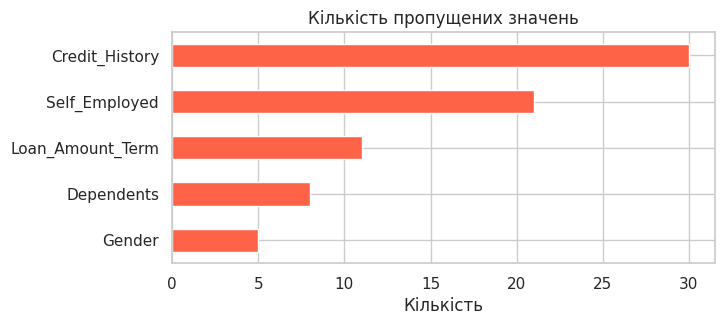

In [111]:
# Візуалізація пропусків
missing[missing > 0].sort_values().plot(kind="barh", color="tomato", figsize=(7, 3))
plt.title("Кількість пропущених значень")
plt.xlabel("Кількість")
plt.show()

## 1.3 Розподіл цільової змінної (Loan_Status)

**Що робимо:** дивимось, скільки займів схвалено, а скільки ні.

**Навіщо:** якщо одного класу набагато більше, модель може «ліниво» завжди відповідати більшим класом. Це треба враховувати при оцінці якості.

Loan_Status
Y    271
N    110
Name: count, dtype: int64

Loan_Status
Y    71.1
N    28.9
Name: proportion, dtype: float64 %


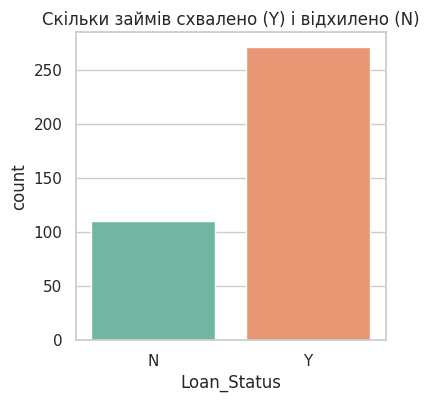

In [112]:
print(df["Loan_Status"].value_counts())
print()
print(df["Loan_Status"].value_counts(normalize=True).round(3) * 100, "%")

plt.figure(figsize=(4, 4))
sns.countplot(data=df, x="Loan_Status", hue="Loan_Status", palette="Set2", legend=False)
plt.title("Скільки займів схвалено (Y) і відхилено (N)")
plt.show()

## 1.4 Розподіл числових змінних

**Технології:** `matplotlib`, `seaborn` (гістограми та boxplot).

**Що робимо:** дивимось, як розподілені доходи, сума і термін займу.

**Навіщо:** видно викиди (дуже великі значення) і те, чи різні масштаби колонок. Саме тому далі потрібна нормалізація (`StandardScaler`).

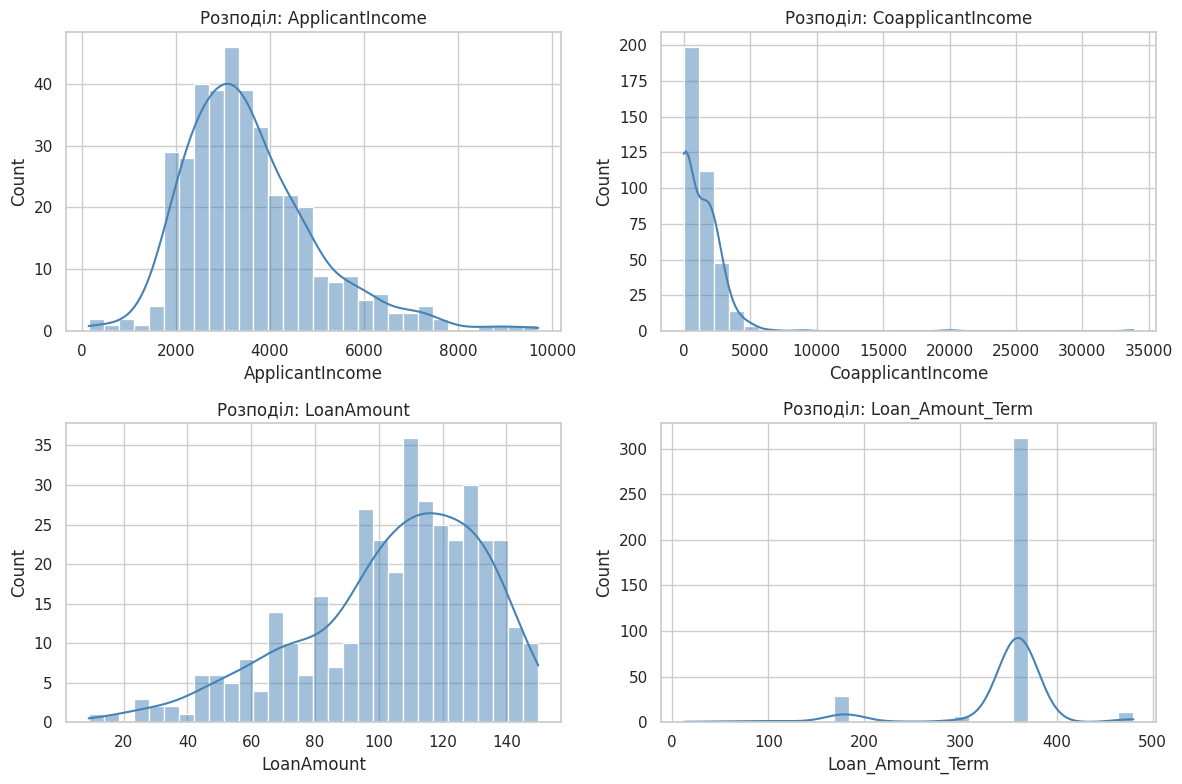

In [113]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Розподіл: {col}")
plt.tight_layout()
plt.show()

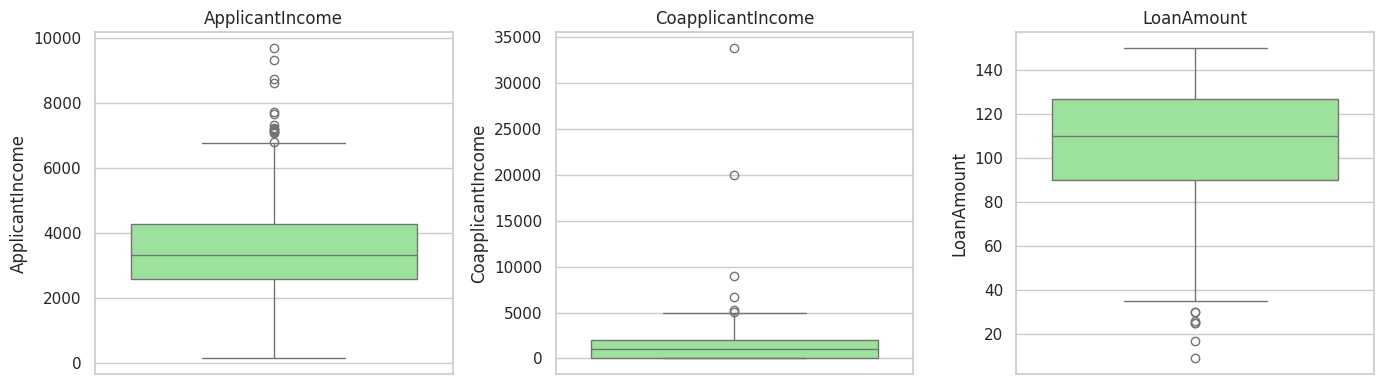

In [114]:
# Boxplot - "коробка з вусами": точки за межами вусів - це викиди
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    sns.boxplot(y=df[col], ax=ax, color="lightgreen")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 1.5 Категоріальні ознаки та їх зв'язок з результатом

**Що робимо:** для кожної текстової колонки будуємо графік: скільки було схвалено (Y) і відхилено (N) в кожній групі.

**Навіщо:** так видно, які ознаки реально впливають на рішення. Якщо стовпчики в групах приблизно однакові, ознака майже не впливає.

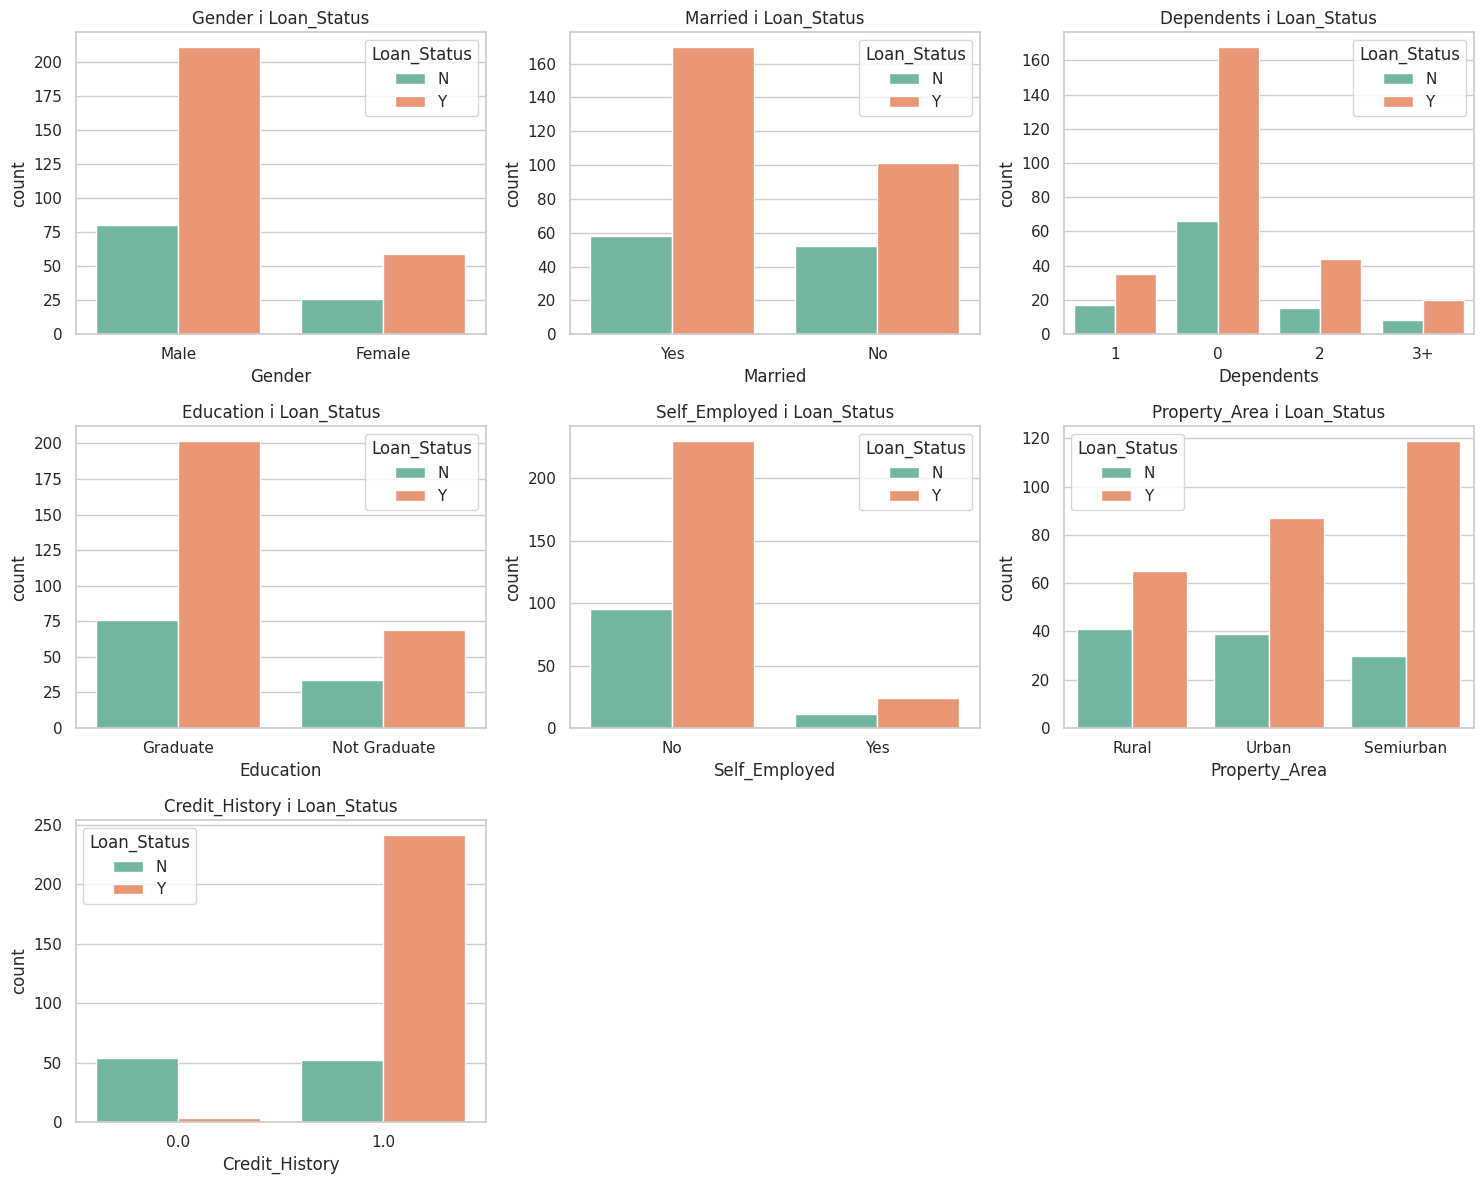

In [115]:
cat_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Credit_History"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=col, hue="Loan_Status", palette="Set2", ax=ax)
    ax.set_title(f"{col} і Loan_Status")
# ховаємо зайві порожні графіки
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [116]:
# Частка схвалених займів (у %) для кожної групи - так легше порівнювати
for col in ["Credit_History", "Property_Area", "Married", "Education"]:
    share = df.groupby(col)["Loan_Status"].apply(lambda s: (s == "Y").mean() * 100).round(1)
    print(f"Частка схвалень (%) за ознакою {col}:")
    print(share.to_string())
    print()

Частка схвалень (%) за ознакою Credit_History:
Credit_History
0.0     5.3
1.0    82.3

Частка схвалень (%) за ознакою Property_Area:
Property_Area
Rural        61.3
Semiurban    79.9
Urban        69.0

Частка схвалень (%) за ознакою Married:
Married
No     66.0
Yes    74.6

Частка схвалень (%) за ознакою Education:
Education
Graduate        72.7
Not Graduate    67.0



## 1.6 Кореляції

**Що робимо:** рахуємо, наскільки кожна ознака пов'язана з результатом. Для цього текстові колонки тимчасово перетворюємо на числа.

**Навіщо:** це відповідає на питання з завдання: *які саме дані впливають на результат*.

**Як читати:** значення від -1 до 1. Ближче до 1 або -1 — зв'язок сильніший; близько 0 — зв'язку майже немає.

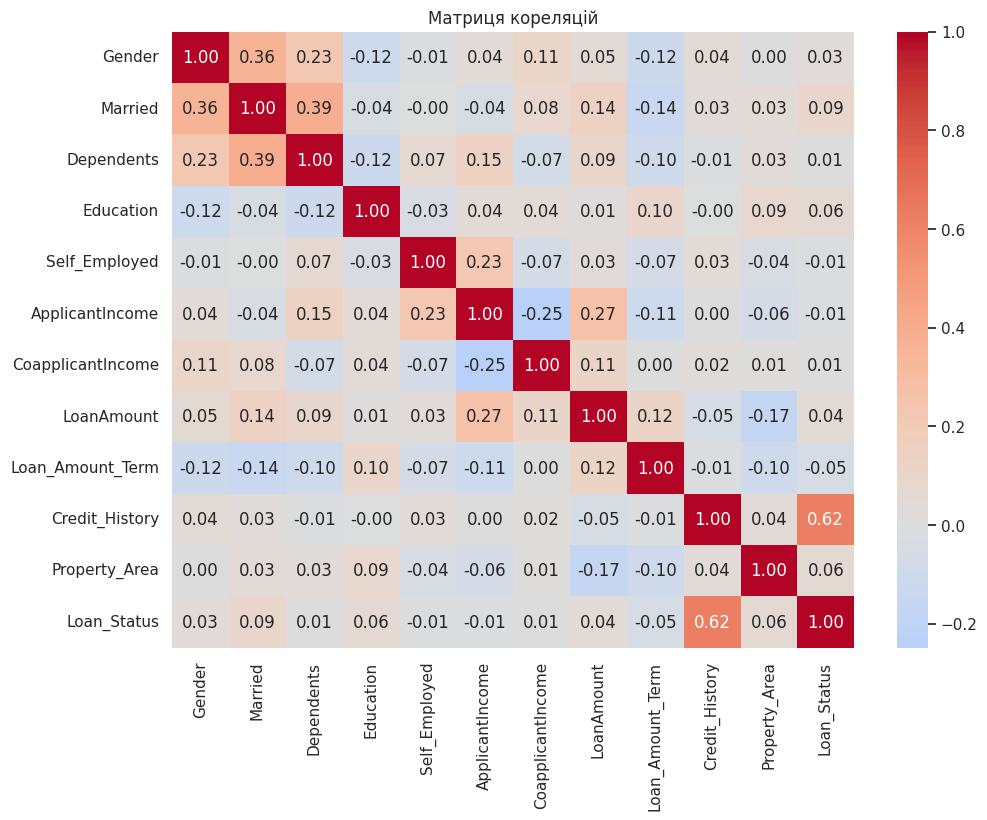

In [117]:
# Копія таблиці, щоб не змінювати оригінал
df_corr = df.copy()

# Текст -> числа (тільки для підрахунку кореляції)
df_corr["Loan_Status"] = df_corr["Loan_Status"].map({"Y": 1, "N": 0})
df_corr["Gender"] = df_corr["Gender"].map({"Male": 1, "Female": 0})
df_corr["Married"] = df_corr["Married"].map({"Yes": 1, "No": 0})
df_corr["Education"] = df_corr["Education"].map({"Graduate": 1, "Not Graduate": 0})
df_corr["Self_Employed"] = df_corr["Self_Employed"].map({"Yes": 1, "No": 0})
df_corr["Dependents"] = df_corr["Dependents"].replace({"3+": 3}).astype(float)
df_corr["Property_Area"] = df_corr["Property_Area"].map({"Rural": 0, "Semiurban": 1, "Urban": 2})

df_corr = df_corr.drop(columns=["Loan_ID"])

plt.figure(figsize=(11, 8))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матриця кореляцій")
plt.show()

Credit_History       0.619
Married              0.092
Property_Area        0.058
Education            0.056
Loan_Amount_Term    -0.048
LoanAmount           0.041
Gender               0.029
Self_Employed       -0.014
ApplicantIncome     -0.010
CoapplicantIncome    0.009
Dependents           0.007
Name: Loan_Status, dtype: float64


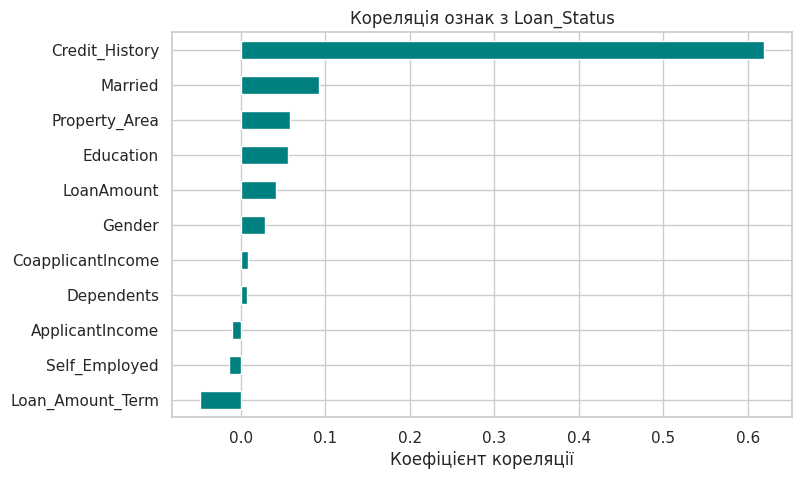

In [118]:
# Кореляція кожної ознаки саме з Loan_Status (від найсильнішої до найслабшої)
target_corr = df_corr.corr()["Loan_Status"].drop("Loan_Status").sort_values(key=abs, ascending=False)
print(target_corr.round(3))

plt.figure(figsize=(8, 5))
target_corr.sort_values().plot(kind="barh", color="teal")
plt.title("Кореляція ознак з Loan_Status")
plt.xlabel("Коефіцієнт кореляції")
plt.show()

### Висновки EDA


- Цільова змінна **не збалансована**: схвалено приблизно 71% займів, відхилено 29%.
- Є пропуски в `Credit_History`, `Self_Employed`, `Loan_Amount_Term`, `Dependents`, `Gender`. Заповнимо їх у Pipeline.
- У доходах є викиди й дуже різні масштаби, тому потрібна нормалізація.
- **Найсильніше з результатом пов'язана `Credit_History`.** Клієнти з хорошою кредитною історією отримують схвалення значно частіше.
- Інші ознаки (стать, освіта, дохід) впливають помітно слабше.

# ЧАСТИНА 2. Моделювання

## 2.1 Підготовка даних

**Що робимо:**
1. Видаляємо `Loan_ID` — це просто номер, він не несе інформації.
2. Відділяємо ознаки `X` (що знаємо про клієнта) від цілі `y` (чи схвалено).
3. Перетворюємо ціль на числа: Y → 1, N → 0.

**Навіщо:** модель вчиться знаходити зв'язок між `X` і `y`.

In [119]:
data = df.drop(columns=["Loan_ID"])

X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"].map({"Y": 1, "N": 0})

print("Ознаки X:", X.shape)
print("Ціль y:", y.shape)

Ознаки X: (381, 11)
Ціль y: (381,)


## 2.2 Розділення на навчальну і тестову вибірки (80 / 20)

**Технологія:** `train_test_split` зі `scikit-learn`.

**Що робимо:** 80% даних віддаємо моделі для навчання, 20% ховаємо для чесної перевірки.

**Навіщо:** якщо перевіряти модель на тих самих даних, на яких вона вчилась, результат буде завищений. Тестові 20% модель ніколи не бачить під час навчання.

`stratify=y` зберігає однакове співвідношення Y/N в обох частинах, `random_state=42` робить результат відтворюваним.

In [120]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% на тест, 80% на навчання
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:  ", X_test.shape)

Навчальна вибірка: (304, 11)
Тестова вибірка:   (77, 11)


## 2.3 Попередня обробка даних (ColumnTransformer)

**Що робимо:** ділимо колонки на числові та категоріальні й обробляємо кожну групу окремо:

| Тип колонок | Що робимо | Інструмент | Навіщо |
|---|---|---|---|
| Числові | заповнюємо пропуски медіаною | `SimpleImputer` | модель не терпить порожніх клітинок |
| Числові | приводимо до одного масштабу | `StandardScaler` | дохід у тисячах, а `Credit_History` 0 або 1: без цього KNN «не помітить» малі числа |
| Категоріальні | заповнюємо пропуски найчастішим значенням | `SimpleImputer` | те саме |
| Категоріальні | текст -> числа (0/1 колонки) | `OneHotEncoder` | моделі працюють лише з числами |

In [121]:
numeric_features = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History"]
categorical_features = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## 2.4 Pipeline + GridSearchCV + перехресна валідація

**Технології:** `Pipeline`, `GridSearchCV`.

**Що таке Pipeline:** «конвеєр», який поєднує обробку даних і модель в один об'єкт. Нові дані автоматично проходять усі кроки. Саме тому Pipeline зручний: на вхід подаємо сирі дані, а на виході отримуємо відповідь.

**Що таке GridSearchCV:** автоматично перебирає комбінації параметрів моделі й для кожної робить **перехресну валідацію** (`cv=5`): навчальні дані ділимо на 5 частин, модель 5 разів навчається на 4 частинах і перевіряється на п'ятій. Так вибираємо найкращі параметри, не торкаючись тестових 20%.

**Моделі:**
- **KNN** (k найближчих сусідів): дивиться на k найбільш схожих клієнтів і голосує за результат.
- **Decision Tree** (дерево рішень): послідовність запитань «так/ні», як блок-схема.
- **Random Forest** (випадковий ліс): багато дерев, які голосують разом. Зазвичай точніше за одне дерево.

In [96]:
# Для кожної моделі: сам Pipeline і сітка параметрів, які GridSearchCV перебиратиме
models = {
    "KNN": (
        Pipeline([("preprocess", preprocessor), ("model", KNeighborsClassifier())]),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11, 15],
            "model__weights": ["uniform", "distance"],
        },
    ),
    "Decision Tree": (
        Pipeline([("preprocess", preprocessor), ("model", DecisionTreeClassifier(random_state=42))]),
        {
            "model__max_depth": [2, 3, 4, 5, 7, None],
            "model__min_samples_leaf": [1, 5, 10, 20],
        },
    ),
    "Random Forest": (
        Pipeline([("preprocess", preprocessor), ("model", RandomForestClassifier(random_state=42))]),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5, 8, None],
            "model__min_samples_leaf": [1, 5, 10],
        },
    ),
}

best_models = {}   # сюди збережемо найкращу версію кожної моделі

for name, (pipe, params) in models.items():
    grid = GridSearchCV(pipe, params, cv=5, scoring="accuracy", n_jobs=-1)
    grid.fit(X_train, y_train)          # навчання + підбір параметрів
    best_models[name] = grid.best_estimator_
    print(f"{name}")
    print("  Найкращі параметри:", grid.best_params_)
    print("  Точність на крос-валідації:", round(grid.best_score_, 3))
    print()

KNN
  Найкращі параметри: {'model__n_neighbors': 11, 'model__weights': 'distance'}
  Точність на крос-валідації: 0.842

Decision Tree
  Найкращі параметри: {'model__max_depth': 2, 'model__min_samples_leaf': 5}
  Точність на крос-валідації: 0.842

Random Forest
  Найкращі параметри: {'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
  Точність на крос-валідації: 0.842



## 2.5 Оцінка моделей на тестових даних (20%)

**Що робимо:** перевіряємо кожну модель на даних, яких вона ще не бачила.

**Метрики:**
- **Accuracy** — частка правильних відповідей.
- **Precision / Recall / F1** — докладніше про якість по кожному класу.
- **Confusion matrix** (матриця помилок) — скільки разів модель помилилась і в який бік.

**Не забуваємо:** якщо завжди відповідати «схвалено», вийде приблизно 71% accuracy (бо стільки схвалених у даних). Тому моделі варто порівнювати з цим базовим рівнем.

In [97]:
baseline = y_test.mean()
print(f"Базовий рівень (завжди відповідати 'схвалено'): {baseline:.3f}")
print()

results = {}
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print("=" * 50)
    print(name, "| Accuracy на тесті:", round(acc, 3))
    print(classification_report(y_test, y_pred, target_names=["Відхилено (0)", "Схвалено (1)"]))

Базовий рівень (завжди відповідати 'схвалено'): 0.714

KNN | Accuracy на тесті: 0.87
               precision    recall  f1-score   support

Відхилено (0)       1.00      0.55      0.71        22
 Схвалено (1)       0.85      1.00      0.92        55

     accuracy                           0.87        77
    macro avg       0.92      0.77      0.81        77
 weighted avg       0.89      0.87      0.86        77

Decision Tree | Accuracy на тесті: 0.857
               precision    recall  f1-score   support

Відхилено (0)       1.00      0.50      0.67        22
 Схвалено (1)       0.83      1.00      0.91        55

     accuracy                           0.86        77
    macro avg       0.92      0.75      0.79        77
 weighted avg       0.88      0.86      0.84        77

Random Forest | Accuracy на тесті: 0.857
               precision    recall  f1-score   support

Відхилено (0)       1.00      0.50      0.67        22
 Схвалено (1)       0.83      1.00      0.91        55



**Як це трактувати:** усі три моделі показують схожу точність, помітно вищу за базовий рівень. Тестова вибірка невелика (77 клієнтів), тож різниця в один-два клієнти не є суттєвою. Модель добре визначає схвалені заявки, але частину відхилених «пропускає» (низький recall для класу «Відхилено»). Це чесне обмеження, про яке варто сказати на презентації.

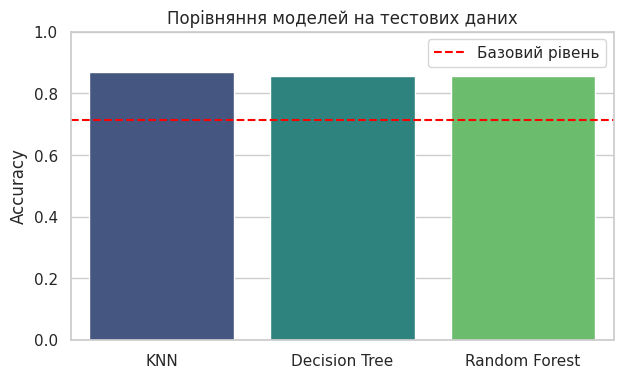

In [98]:
# Порівняння моделей на одному графіку
plt.figure(figsize=(7, 4))
sns.barplot(x=list(results.keys()), y=list(results.values()), hue=list(results.keys()), palette="viridis", legend=False)
plt.axhline(baseline, color="red", linestyle="--", label="Базовий рівень")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Порівняння моделей на тестових даних")
plt.legend()
plt.show()

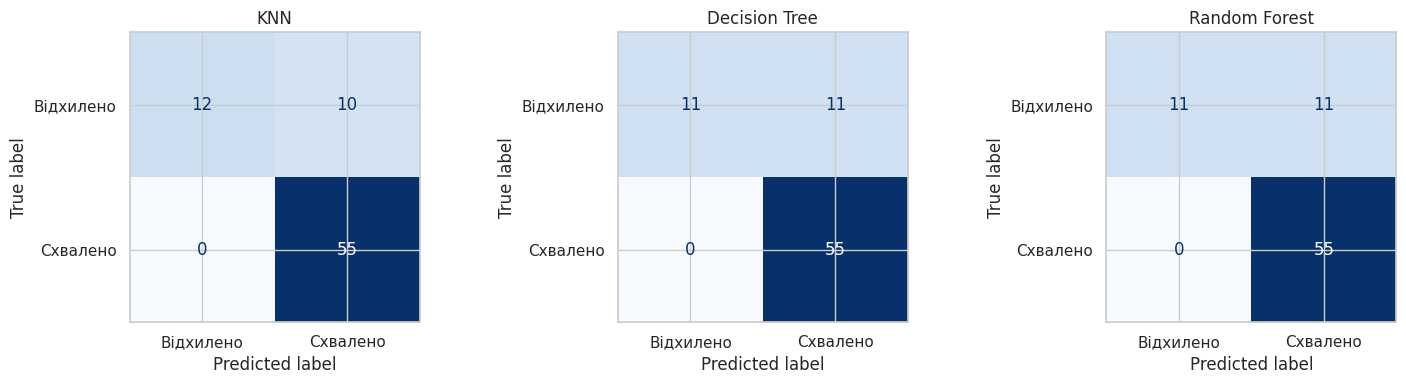

In [99]:
# Матриці помилок для всіх трьох моделей
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, cmap="Blues",
        display_labels=["Відхилено", "Схвалено"], colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 2.6 Важливість ознак (Feature Importance)

**Що робимо:** питаємо в Random Forest, які ознаки найбільше допомагали ухвалювати рішення.

**Навіщо:** відповідь на питання «що найбільше впливає на схвалення займу». Це підтверджує (або спростовує) висновки з кореляцій.

Назви на графіку на кшталт `cat__Married_Yes` означають: категорія `Married`, значення `Yes` (після OneHotEncoder).

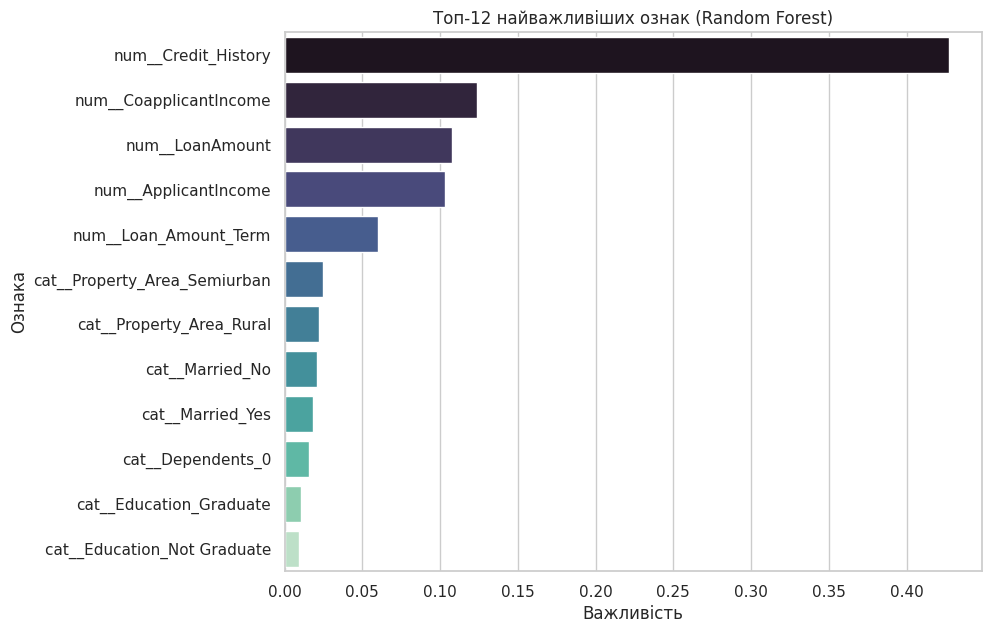

,Ознака,Важливість
4,num__Credit_History,0.427064
1,num__CoapplicantIncome,0.123780
2,num__LoanAmount,0.107706
0,num__ApplicantIncome,0.103381
3,num__Loan_Amount_Term,0.059959
18,cat__Property_Area_Semiurban,0.024443
17,cat__Property_Area_Rural,0.021949
7,cat__Married_No,0.020623
8,cat__Married_Yes,0.018099
9,cat__Dependents_0,0.015839


In [100]:
rf_pipeline = best_models["Random Forest"]

feature_names = rf_pipeline.named_steps["preprocess"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

importance_df = (
    pd.DataFrame({"Ознака": feature_names, "Важливість": importances})
    .sort_values("Важливість", ascending=False)
)

plt.figure(figsize=(9, 7))
sns.barplot(data=importance_df.head(12), x="Важливість", y="Ознака", hue="Ознака", palette="mako", legend=False)
plt.title("Топ-12 найважливіших ознак (Random Forest)")
plt.show()

importance_df.head(10)

## 2.7 Як мислить дерево рішень

**Що робимо:** малюємо невелике дерево рішень.

**Навіщо:** це наочно показує логіку моделі у вигляді запитань «так/ні». Добре підходить для демонстрації на презентації.

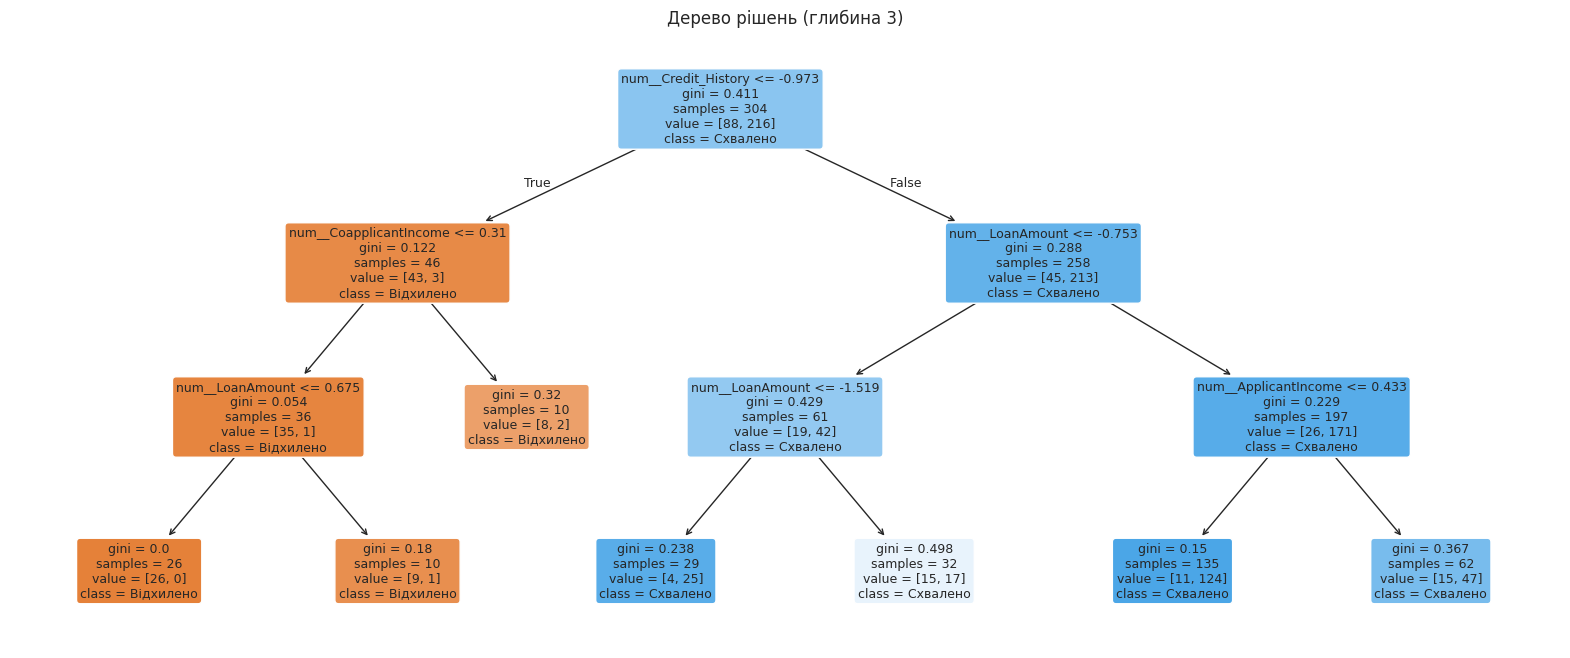

In [101]:
# Окреме неглибоке дерево (глибина 3), щоб воно вміщалося на екран
tree_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42))
])
tree_pipe.fit(X_train, y_train)

plt.figure(figsize=(20, 8))
plot_tree(
    tree_pipe.named_steps["model"],
    feature_names=tree_pipe.named_steps["preprocess"].get_feature_names_out(),
    class_names=["Відхилено", "Схвалено"],
    filled=True, rounded=True, fontsize=9
)
plt.title("Дерево рішень (глибина 3)")
plt.show()

## 2.8 Вибір найкращої моделі та збереження

**Що робимо:** вибираємо модель з найвищою точністю на тесті та зберігаємо її у файл `loan_model.joblib`.

**Навіщо:** збережену модель можна будь-коли завантажити й отримувати прогноз без повторного навчання.

In [102]:
best_name = max(results, key=results.get)
final_model = best_models[best_name]

print("Найкраща модель:", best_name, "| Accuracy:", round(results[best_name], 3))

joblib.dump(final_model, "loan_model.joblib")
print("Модель збережено у файл loan_model.joblib")

Найкраща модель: KNN | Accuracy: 0.87
Модель збережено у файл loan_model.joblib


## 2.9 Перевірка прогнозу на новому клієнті

**Що робимо:** вручну створюємо одного нового клієнта і просимо модель передбачити результат.

**Навіщо:** так модель працюватиме на нових даних: ми подаємо дані клієнта, а вона повертає «схвалено» або «відхилено».

In [103]:
new_client = pd.DataFrame([{
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "0",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 4000,
    "CoapplicantIncome": 1500,
    "LoanAmount": 120,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban",
}])

prediction = final_model.predict(new_client)[0]
probability = final_model.predict_proba(new_client)[0][1]

print("Результат:", "Займ СХВАЛЕНО" if prediction == 1 else "Займ ВІДХИЛЕНО")
print(f"Імовірність схвалення: {probability:.0%}")

Результат: Займ СХВАЛЕНО
Імовірність схвалення: 83%


In [104]:
# Те саме, але з поганою кредитною історією - порівняйте результат
bad_client = new_client.copy()
bad_client["Credit_History"] = 0.0

prediction = final_model.predict(bad_client)[0]
probability = final_model.predict_proba(bad_client)[0][1]

print("Результат:", "Займ СХВАЛЕНО" if prediction == 1 else "Займ ВІДХИЛЕНО")
print(f"Імовірність схвалення: {probability:.0%}")

Результат: Займ ВІДХИЛЕНО
Імовірність схвалення: 7%


## Підсумок

1. Проаналізовано дані: розподіли, пропуски, кореляції.
2. Дані розділено 80/20, підготовлено через `Pipeline` (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`).
3. Навчено три моделі (KNN, Decision Tree, Random Forest), параметри підібрано через `GridSearchCV` з перехресною валідацією.
4. Моделі порівняно за точністю та матрицями помилок; визначено найважливіші ознаки.
5. Найкращу модель збережено у файл `loan_model.joblib`.